# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [44]:
import os

from pandas.api.types import is_string_dtype, is_numeric_dtype

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Import US states shapefile

In [3]:
fp = os.path.join('data', 'tl_2026_us_state', 'tl_2026_us_state.shp')
states = gpd.read_file(fp)

states.head(3)

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


In [4]:
# Create geodataframe from CSV, known for metadata: CRS of the power plants data has the code EPSG: 4269

# Create points from latitude and longitude
points = gpd.points_from_xy(power_plants['longitude'], 
                            power_plants['latitude'])
print(points)

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants,    # Data
                                geometry=points, # Specify geometry column
                                crs='EPSG:4269'  # Specify CRS
                                )

<GeometryArray>
[ <POINT (-84.295 45.363)>,  <POINT (-83.328 43.466)>,
  <POINT (-82.939 43.722)>,  <POINT (-85.426 43.839)>,
  <POINT (-85.855 42.731)>,  <POINT (-84.914 43.402)>,
  <POINT (-92.162 47.531)>,  <POINT (-94.359 45.861)>,
  <POINT (-93.653 47.261)>,  <POINT (-92.294 46.667)>,
 ...
    <POINT (-76.53 37.36)>,  <POINT (-79.398 39.373)>,
  <POINT (-79.404 39.375)>,  <POINT (-68.801 44.849)>,
  <POINT (-68.706 44.842)>, <POINT (-118.109 34.608)>,
  <POINT (-79.282 42.503)>,  <POINT (-77.743 43.189)>,
  <POINT (-75.903 42.338)>, <POINT (-120.634 37.084)>]
Length: 13445, dtype: geometry


In [6]:
power_plants.geometry

0         POINT (-84.29497 45.36282)
1         POINT (-83.32781 43.46590)
2         POINT (-82.93881 43.72170)
3         POINT (-85.42600 43.83930)
4         POINT (-85.85510 42.73100)
                    ...             
13440    POINT (-118.10900 34.60800)
13441     POINT (-79.28172 42.50275)
13442     POINT (-77.74272 43.18914)
13443     POINT (-75.90345 42.33782)
13444    POINT (-120.63443 37.08391)
Name: geometry, Length: 13445, dtype: geometry

<Axes: >

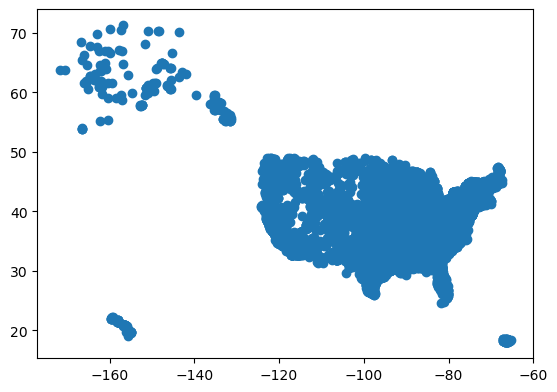

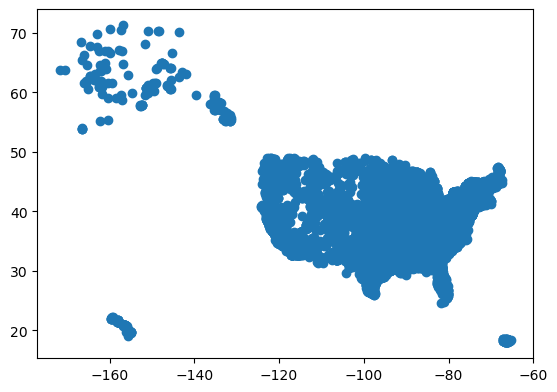

In [8]:
power_plants.plot()

In [9]:
# f-string
print('CRS', power_plants.crs)

CRS EPSG:4269


In [10]:
print(f"ellipsoid: {power_plants.crs.ellipsoid}")

ellipsoid: GRS 1980


In [11]:
print(f"The data has {len(power_plants):,} power plants")

The data has 13,445 power plants


In [12]:
print(f"Average installed capacity {power_plants['install_mw'].mean():.2f} MW")

Average installed capacity 99.39 MW


In [ ]:
# For Loops

EPSG:4269


<Axes: >

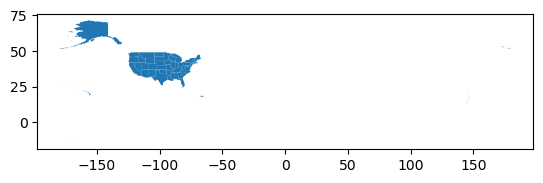

In [13]:
print(states.crs)
states.plot()

In [14]:
states.head(3)

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


In [15]:
# Simplify column names

states.columns = states.columns.str.lower()

states.columns

Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')

In [16]:
# Check data type of a few codes columns

print(f"regions is string dtype? {is_string_dtype(states['region'])}")

regions is string dtype? True


In [17]:
is_string_dtype(states['region'])

True

In [18]:
# Another way of calling the function
pd.api.types.is_string_dtype(states['region'])

True

In [19]:
print(f"region is string dtype? {is_string_dtype(states['region'])}")
print(f"division is string dtype? {is_string_dtype(states['division'])}")
print(f"statefp is string dtype? {is_string_dtype(states['statefp'])}")

region is string dtype? True
division is string dtype? True
statefp is string dtype? True


In [20]:
code_cols = ['region', 'division', 'statefp']

# Check whether codes columns are strings
for column in code_cols: 
    print(f"{column} is string dtype? {is_string_dtype(states[column])}")

region is string dtype? True
division is string dtype? True
statefp is string dtype? True


In [21]:
# Update code columns into integers
# The assert keyword does nothing if the expression next to it evaluates to True
for column in code_cols:
    states[column] = states[column].astype('int')
    assert is_numeric_dtype(states[column])  # Check conversion

In [22]:
# How does `assert` work?
# Does nothing if statement is True
assert 2+2 == 4

In [24]:
# Raises an error if statement is False
assert 2+2 == 4

# sum = 3 +2
# assert sum == 4, "sum is not equal to 4" <- error message prints, always needs to be a boolean (evaluate to True or False)

In [25]:
# Subset data

# column names for columns with code
code_cols

['region', 'division', 'statefp']

In [27]:
for column in code_cols:
    print(f"{column}: {sorted(states[column].unique())}")

region: [1, 2, 3, 4, 9]
division: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
statefp: [1, 2, 4, 5, 6, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 44, 45, 46, 47, 48, 49, 50, 51, 53, 54, 55, 56, 60, 66, 69, 72, 78]


In [31]:
states[states['region']==9]['name']

3                                   American Samoa
28                    United States Virgin Islands
47                                     Puerto Rico
53    Commonwealth of the Northern Mariana Islands
54                                            Guam
Name: name, dtype: object

In [38]:
contiguous = states[(states['region'] != 9) & (~states['statefp'].isin([2,15]))]

In [39]:
contiguous_pp = power_plants[~power_plants['state'].isin(['Puerto Rico', 'Hawaii', 'Alaska'])]

In [40]:
contiguous_pp

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude,geometry
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818,POINT (-84.29497 45.36282)
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899,POINT (-83.32781 43.46590)
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699,POINT (-82.93881 43.72170)
3,62900,1877,George Johnson,20910,Wolverine Power Supply Coop,Electric Utility,1529 S 170th Ave,Hersey,Osceola,Michigan,49639,natural gas,"Natural Gas = 48.7 MW, Petroleum = 1 MW",Natural Gas Fired Combustion Turbine; Petroleu...,51.0,49.7,0.0,0.0,0.0,0.0,0.0,0.0,48.7,0.0,1.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-85.426003,43.839298,POINT (-85.42600 43.83930)
4,62901,1880,Claude Vandyke,20910,Wolverine Power Supply Coop,Electric Utility,3150 143rd Ave,Dorr,Allegan,Michigan,49323,natural gas,Natural Gas = 20.2 MW,Natural Gas Fired Combustion Turbine,24.8,20.2,0.0,0.0,0.0,0.0,0.0,0.0,20.2,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-85.855104,42.731000,POINT (-85.85510 42.73100)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13440,75538,68798,Lockheed Martin Palmdale Solar PV,57266,Lockheed Martin Corporation,Industrial Non-CHP,NaN,NaN,NaN,California,0,solar,Solar = 20 MW,Solar Photovoltaic,20.9,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-118.109000,34.608000,POINT (-118.10900 34.60800)
13441,75539,68804,Rivard 1,61194,Generate Capital,IPP Non-CHP,NaN,NaN,NaN,New York,0,solar,Solar = 4.6 MW,Solar Photovoltaic,4.6,4.6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.6,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-79.281719,42.502749,POINT (-79.28172 42.50275)
13442,75540,68806,Ridgeway 2,61194,Generate Capital,IPP Non-CHP,NaN,NaN,NaN,New York,0,solar,Solar = 2.5 MW,Solar Photovoltaic,2.5,2.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.5,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-77.742717,43.189136,POINT (-77.74272 43.18914)
13443,75541,68807,Catskill,61194,Generate Capital,IPP Non-CHP,NaN,NaN,NaN,New York,0,solar,Solar = 3.8 MW,Solar Photovoltaic,3.8,3.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.8,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-75.903449,42.337824,POINT (-75.90345 42.33782)


In [41]:
assert contiguous.crs == contiguous_pp.crs

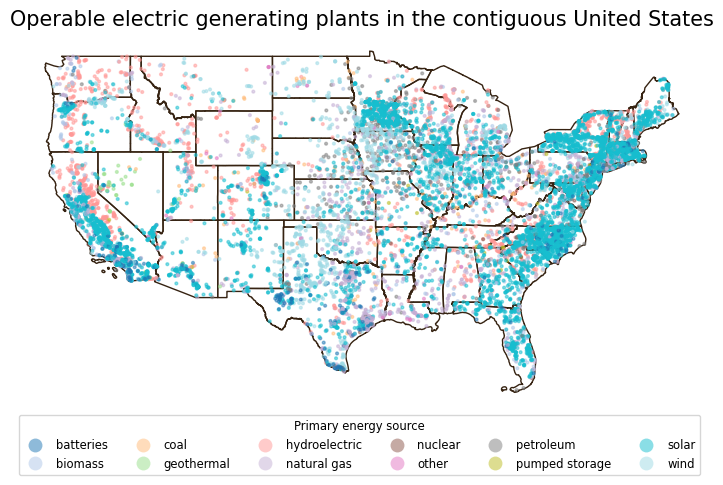

In [47]:
fig, ax = plt.subplots(figsize=(9, 5)) # Update figure size

# Remove the axis for a cleaner map
ax.axis('off')

# Title for the plot
ax.set_title('Operable electric generating plants in the contiguous United States', 
              fontsize=15)

# Add states
contiguous.plot(ax=ax,
               color='none',
               edgecolor='#362312')

# Add electric power plants colored by energy source
contiguous_pp.plot(ax=ax, 
                  column='primsource',
                  legend=True,
                  markersize=4,
                  cmap='tab20',
                  alpha=0.5,
                  legend_kwds={
                      'title': 'Primary energy source',
                      'title_fontsize': 'small',
                      'fontsize': 'small',
                      'loc': 'upper left',
                      'bbox_to_anchor': (0, 0),
                      'ncols': 6  
                  })
                  
plt.show()

In [ ]:
## 'for' with 'zip': often we need to simultaneously iterate over two lists
# 'zip()' lets you combine two or more lists to iterate over time

In [49]:
# Iterate over a single list
numbers = [1,2,3]
for x in numbers:
    print(x)

print('\n') # Blank line

# Iterate over two lists in pairs using zip()
numbers = [1,2,3]
letters = ['a', 'b', 'c']
for x, letter in zip(numbers, letters):
    print(x, letter)

1
2
3


1 a
2 b
3 c


In [51]:
numbers = [1,2,3]
letters = ['a', 'b', 'c']
for x in numbers:
    print(letter in letters)

True
True
True


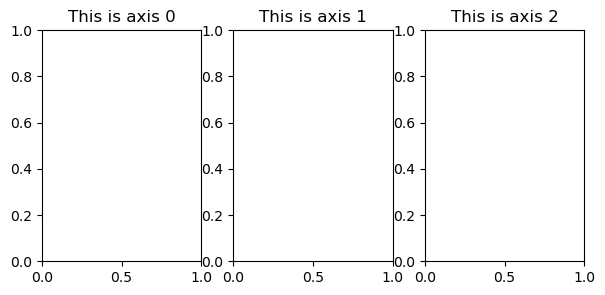

In [52]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))

axes[0].set_title('This is axis 0')
axes[1].set_title('This is axis 1')
axes[2].set_title('This is axis 2')

plt.show()

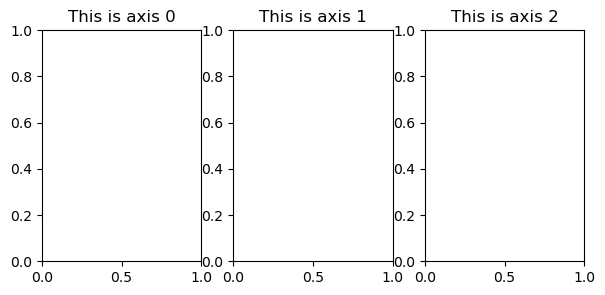

In [55]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7, 3))
for ax, i in zip(axes, [0,1,2]):
    ax.set_title(f'This is axis {i}')
plt.show()

In [56]:
ca_power_plants = power_plants[power_plants['state'].isin(['California'])]

In [57]:
ca_power_plants

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude,geometry
421,62116,34,Rollins,13402,Nevada Irrigation District,IPP Non-CHP,15531 Arrow Head Lane,Colfax,Placer,California,95713,hydroelectric,Hydroelectric = 12.1 MW,Conventional Hydroelectric,12.1,12.1,0.0,0.0,0.0,0.0,12.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.953337,39.134255,POINT (-120.95334 39.13426)
443,62136,72,Venice Hydro,12397,Metropolitan Water District of S CA,Electric Utility,3815 Sepulveda Blvd,Culver City,Los Angeles,California,90230,hydroelectric,Hydroelectric = 10.1 MW,Conventional Hydroelectric,10.1,10.1,0.0,0.0,0.0,0.0,10.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-118.416798,34.011351,POINT (-118.41680 34.01135)
459,62152,104,J S Eastwood,17609,Southern California Edison Co,Electric Utility,Hwy 168 Sierra National Forest,Shaver Lake,Fresno,California,93664,pumped storage,Pumped Storage = 199.8 MW,Hydroelectric Pumped Storage,199.8,199.8,0.0,0.0,0.0,0.0,0.0,199.8,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-119.256698,37.147920,POINT (-119.25670 37.14792)
480,62172,151,McClure,12745,Modesto Irrigation District,Electric Utility,639 S. McClure Rd.,Modesto,Stanislaus,California,95354,natural gas,"Natural Gas = 53.5 MW, Petroleum = 53.5 MW",Natural Gas Fired Combustion Turbine; Petroleu...,142.4,107.0,0.0,0.0,0.0,0.0,0.0,0.0,53.5,0.0,53.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.931390,37.629358,POINT (-120.93139 37.62936)
486,62178,161,Turlock Lake,19281,Turlock Irrigation District,Electric Utility,21642 Davis Road,Hickman,Stanislaus,California,95323,hydroelectric,Hydroelectric = 3.3 MW,Conventional Hydroelectric,3.3,3.3,0.0,0.0,0.0,0.0,3.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.594677,37.611457,POINT (-120.59468 37.61146)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13337,75435,68630,Sutter Home Winery TCC,67006,"REC SHW, LLC",IPP Non-CHP,NaN,NaN,NaN,California,0,solar,Solar = 1.1 MW,Solar Photovoltaic,1.1,1.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.1,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.685272,35.735604,POINT (-120.68527 35.73560)
13340,75438,68634,Avalon Dairy,64698,"Renewable Solar, Inc",Industrial Non-CHP,NaN,NaN,NaN,California,0,solar,Solar = 3.1 MW,Solar Photovoltaic,3.1,3.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.1,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-119.430361,35.716445,POINT (-119.43036 35.71645)
13426,75524,68749,Superior Almond Hulling,64698,"Renewable Solar, Inc",Industrial Non-CHP,NaN,NaN,NaN,California,0,solar,Solar = 2.1 MW,Solar Photovoltaic,2.1,2.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.1,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-120.387423,36.442187,POINT (-120.38742 36.44219)
13440,75538,68798,Lockheed Martin Palmdale Solar PV,57266,Lockheed Martin Corporation,Industrial Non-CHP,NaN,NaN,NaN,California,0,solar,Solar = 20 MW,Solar Photovoltaic,20.9,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-118.109000,34.608000,POINT (-118.10900 34.60800)


In [64]:
top_sources = ca_power_plants['primsource'].value_counts().index[:3].tolist()

In [ ]:
# Isolate to CA boundry

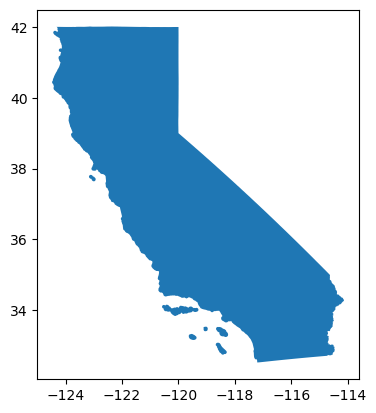

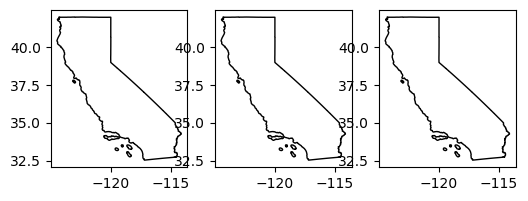

In [68]:
ca_boundary = states[states['name']== 'California']
ca_boundary.plot()


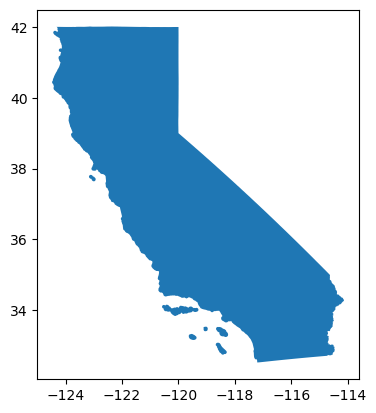

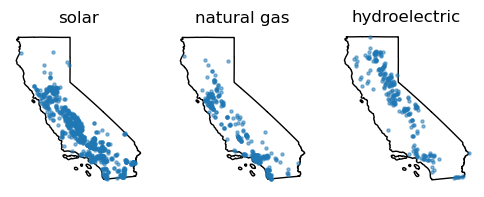

In [72]:
ca_boundary = states[states['name']== 'California']
ca_boundary.plot()


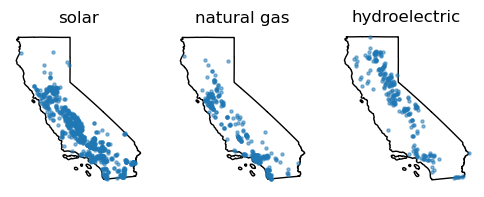

In [73]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=((6,3)))

for ax, source in zip(axes, top_sources):
    ca_boundary.plot(ax=ax, color='none')
    
    subset = ca_power_plants[ca_power_plants['primsource']== source]
    subset.plot(ax=ax, markersize=5, alpha=0.5)
    ax.set_title(source)
    ax.axis('off')

plt.show()